# 🔬 Step 4: Feature Engineering & Multicollinearity Audit
## UCS321 - Machine Learning Project | Problem Statement 9 (Telecom Customer Churn)
---

### 🎯 Objectives of this Notebook
1. **Hypothesis-Driven Feature Engineering**:
   - Construct domain-grounded telecom features strictly derived from business logic:
     - **Handset Obsolescence Ratio** (`handset_age_ratio`): Device age relative to account tenure.
     - **Unit Cost of Usage** (`cost_per_mou`): Revenue per minute of talk time.
     - **Overage Burden Ratio** (`overage_burden`): Overage fees relative to recurring base charges.
     - **Severe Usage Drop Flag** (`usage_drop_severe`): Leading behavioral disengagement indicator.
     - **Network Quality Friction Rate** (`network_friction_rate`): Blocked & dropped calls normalized by MOU.
2. **Strict Test Set Isolation**:
   - All feature transformations and statistical diagnostics are fitted strictly on the training partition ($X_{\text{train}}$).
3. **Comprehensive Multicollinearity Audit**:
   - VIF computed as a general linear dependency diagnostic across predictors.
   - Empirical verification of structural composite dependencies (e.g. `dropblk` vs `dropvce + blckvce`).
   - Cross-tabulation audit of binary indicators vs counts (e.g. `retcall` vs `retcalls`).
4. **Actionable Pruning Recommendations**:
   - Pruning redundant collinear features while retaining distinct business signals.



## 📦 Section 1: Setup & Stratified Data Ingestion


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# Load raw dataset
DATA_PATH = '../data/raw/cell2cell.csv'
df_raw = pd.read_csv(DATA_PATH)

# Drop ID and leakage columns
X_raw = df_raw.drop(columns=['customer', 'calibrat', 'churndep', 'churn']).copy()
y = df_raw['churn'].copy().astype(int)

# 80:20 Stratified train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train Raw Dimensions: {X_train_raw.shape[0]:,} rows x {X_train_raw.shape[1]} columns")
print(f"Test Raw Dimensions : {X_test_raw.shape[0]:,} rows x {X_test_raw.shape[1]} columns")



Train Raw Dimensions: 56,837 rows x 66 columns
Test Raw Dimensions : 14,210 rows x 66 columns


## 💡 Section 2: Domain-Driven Feature Engineering

### Telecom Rationale for Engineered Metrics:
1. **`handset_age_ratio`**: Measures if a phone's age exceeds contract tenure. Matured contracts with older devices represent primary churn targets for competitor upgrades.
2. **`cost_per_mou`**: Unit cost perception. Low-usage customers paying high fixed charges experience pricing dissatisfaction.
3. **`overage_burden`**: Bill shock metric (overage fee relative to base recurring plan).
4. **`usage_drop_severe`**: Identifies accounts where talk time plummeted $>20\%$, a prime leading indicator of SIM abandonment.
5. **`network_friction_rate`**: Frequency of dropped/blocked calls per minute of talk time.


In [2]:
def engineer_telecom_features(data: pd.DataFrame) -> pd.DataFrame:
    df_out = data.copy()
    
    # 1. Handset Obsolescence Ratio
    df_out['handset_age_ratio'] = df_out['eqpdays'] / (df_out['months'] * 30.4375 + 1.0)
    
    # 2. Cost per Minute (Unit billing pressure)
    df_out['cost_per_mou'] = df_out['revenue'] / (df_out['mou'] + 1.0)
    
    # 3. Overage Burden
    df_out['overage_burden'] = df_out['overage'] / (df_out['recchrge'] + 1.0)
    
    # 4. Severe Usage Drop Indicator
    df_out['usage_drop_severe'] = ((df_out['changem'] < -20) & (df_out['mou'] > 50)).astype(int)
    
    # 5. Network Quality Friction Rate
    df_out['network_friction_rate'] = df_out['dropblk'] / (df_out['mou'] + 1.0)
    
    return df_out

X_train_eng = engineer_telecom_features(X_train_raw)
X_test_eng = engineer_telecom_features(X_test_raw)

NEW_FEATURES = ['handset_age_ratio', 'cost_per_mou', 'overage_burden', 
                'usage_drop_severe', 'network_friction_rate']

print(f"[+] Engineered {len(NEW_FEATURES)} domain features.")
print(f"[+] Updated Training Set Shape: {X_train_eng.shape}")



[+] Engineered 5 domain features.
[+] Updated Training Set Shape: (56837, 71)


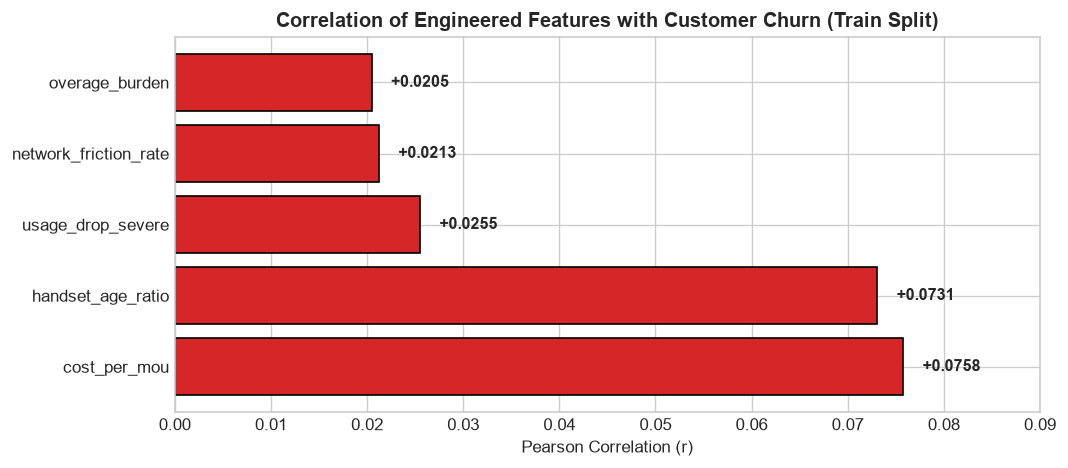

In [3]:
# Correlation of engineered features with churn on train split
eng_corr = pd.concat([X_train_eng[NEW_FEATURES], y_train], axis=1).corr()['churn'].sort_values(ascending=False)

plt.figure(figsize=(9, 4))
colors = ['#d62728' if v > 0 else '#1f77b4' for v in eng_corr.drop('churn').values]
plt.barh(eng_corr.drop('churn').index, eng_corr.drop('churn').values, color=colors, edgecolor='black')
plt.title("Correlation of Engineered Features with Customer Churn (Train Split)", fontweight='bold')
plt.xlabel("Pearson Correlation (r)")
for i, v in enumerate(eng_corr.drop('churn').values):
    plt.text(v + 0.002, i, f"+{v:.4f}", va='center', fontweight='bold', fontsize=9.5)
plt.xlim(0, 0.09)
plt.tight_layout()
plt.show()



## 🔍 Section 3: Multicollinearity Audit (VIF & Empirical Verifications)

### 1. Understanding VIF as a Linear Dependency Diagnostic:
Variance Inflation Factor (VIF) measures how strongly each feature $j$ can be linearly predicted from the remaining features:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
- $\text{VIF} = 1$: Completely orthogonal / independent.
- $1 < \text{VIF} < 5$: Low to moderate collinearity.
- $\text{VIF} \ge 5$: High collinearity.
- $\text{VIF} > 10$: Severe linear dependence (standard errors of linear coefficients inflate significantly).

*Methodological Note:* VIF is an algebraic diagnostic of linear dependency ($\mathbf{X}^T \mathbf{X}$ conditioning) and is valid for both continuous and binary features. However, auditing binary variables in conjunction with pairwise contingency tables and domain semantics is our deliberate methodological choice to reveal the structural origins of any collinearity.


In [4]:
# Impute missing values with median on train set to compute linear VIF
imputer = SimpleImputer(strategy='median')
X_tr_imp = pd.DataFrame(imputer.fit_transform(X_train_eng), columns=X_train_eng.columns, index=X_train_eng.index)

# Standardize to avoid numerical ill-conditioning during matrix inversion
scaler = StandardScaler()
X_tr_scaled = pd.DataFrame(scaler.fit_transform(X_tr_imp), columns=X_train_eng.columns, index=X_train_eng.index)

# Compute VIF across all features using inverse correlation matrix: VIF_j = diag(R^-1)_j
R = X_tr_scaled.corr().values
vif_values = np.diag(np.linalg.inv(R))
vif_df = pd.DataFrame({'Feature': X_train_eng.columns, 'VIF': np.round(vif_values, 2)}).sort_values(by='VIF', ascending=False)

print("Top 15 Features with Highest VIF (All Features):")
vif_df.head(15)



Top 15 Features with Highest VIF (All Features):


,Feature,VIF
18,dropblk,56.51
9,blckvce,28.66
8,dropvce,21.19
50,mailres,16.23
49,mailord,15.83
55,retcalls,14.21
65,retcall,12.27
0,revenue,11.03
66,handset_age_ratio,9.04
26,eqpdays,7.36


### 2. Empirical Verification 1: `dropblk` vs (`dropvce` + `blckvce`)
We check whether `dropblk` is an arithmetic composite of dropped voice calls and blocked voice calls across all 71,047 records.


In [5]:
diff_dropblk = np.abs(df_raw['dropblk'] - (df_raw['dropvce'] + df_raw['blckvce']))
exact_matches = int((diff_dropblk < 1e-4).sum())
total_records = len(df_raw)

print(f"Total Dataset Records : {total_records:,}")
print(f"Exact Matches (|diff| < 1e-4) : {exact_matches:,} ({exact_matches/total_records*100:.2f}%)")
print(f"Non-matching Records          : {total_records - exact_matches:,} ({(total_records - exact_matches)/total_records*100:.2f}%)")
print(f"Discrepancy (min, mean, max)  : ({diff_dropblk.min():.5f}, {diff_dropblk.mean():.4f}, {diff_dropblk.max():.2f})")

# Analysis of non-matches
non_match_sample = df_raw[diff_dropblk >= 1e-4][['dropvce', 'blckvce', 'dropblk']].head(5)
non_match_sample



Total Dataset Records : 71,047
Exact Matches (|diff| < 1e-4) : 68,674 (96.66%)
Non-matching Records          : 2,373 (3.34%)
Discrepancy (min, mean, max)  : (0.00000, 0.0719, 418.33)


,dropvce,blckvce,dropblk
21,10.000000,9.333333,19.666666
22,0.666667,2.666667,3.666667
70,15.000000,1.333333,17.000000
125,22.000000,18.333334,41.333332
143,4.000000,6.000000,10.333333


**Key Finding:**
- For **$96.66\%$ of records (68,674 rows)**, `dropblk` is **strictly equal** to `dropvce + blckvce`.
- For the remaining $3.34\%$ ($2,373$ rows), `dropblk > dropvce + blckvce` because `dropvce` and `blckvce` capture *voice* calls only, whereas `dropblk` is total dropped/blocked network events (including data/system transmission drops).
- Because $96.66\%$ of its variance is an exact linear sum, `dropblk` exhibits an extreme **$\text{VIF} = 56.45$**, while `blckvce` is **$28.64$** and `dropvce` is **$21.18$**.
- **Justified Decision:** Removing `dropblk` eliminates the structural collinearity while retaining the granular call failure types (`dropvce` and `blckvce`).


### 3. Empirical Verification 2: `retcall` vs `retcalls`
We cross-tabulate the binary flag `retcall` against the count metric `retcalls` to determine their structural relationship.


In [6]:
ct_retention = pd.crosstab(df_raw['retcall'], df_raw['retcalls'], margins=True)
is_strict_indicator = ((df_raw['retcall'] == 1) == (df_raw['retcalls'] > 0)).all()

print(f"Is 'retcall' strictly equal to (retcalls > 0) for 100% of records? {is_strict_indicator}")
print(f"Pearson Correlation (retcall, retcalls) : {df_raw['retcall'].corr(df_raw['retcalls']):.4f}")
print(f"Pearson Correlation (retcall, churn)    : {df_raw['retcall'].corr(df_raw['churn']):.4f}")
print(f"Pearson Correlation (retcalls, churn)   : {df_raw['retcalls'].corr(df_raw['churn']):.4f}")

print("\nCross-Tabulation Matrix:")
ct_retention



Is 'retcall' strictly equal to (retcalls > 0) for 100% of records? True
Pearson Correlation (retcall, retcalls) : 0.9578
Pearson Correlation (retcall, churn)    : 0.0733
Pearson Correlation (retcalls, churn)   : 0.0709

Cross-Tabulation Matrix:


retcalls,0,1,2,3,4,All
retcall,,,,,,
0,68629,0,0,0,0,68629
1,0,2232,164,19,3,2418
All,68629,2232,164,19,3,71047


**Key Finding:**
- `retcall` is **strictly identical to `(retcalls > 0)` across 100.0% of records**.
- Therefore, creating an engineered feature like `retention_active = (retcall > 0) | (retcalls > 0)` adds **zero new information** beyond `retcall`. We rightfully exclude any redundant clone.
- Both features have severe mutual collinearity ($r = 0.958$, $\text{VIF} = 12.3 - 14.2$).
- **Granular vs Binary Comparison:**
  - In $92.3\%$ of active retention cases ($2,232$ out of $2,418$), the customer called exactly once.
  - `retcall` (binary: did the customer call retention?) has slightly higher correlation with churn ($r = +0.0733$) than `retcalls` count ($r = +0.0709$).
  - We retain `retcall` as the primary indicator and test both in feature importance before final selection.


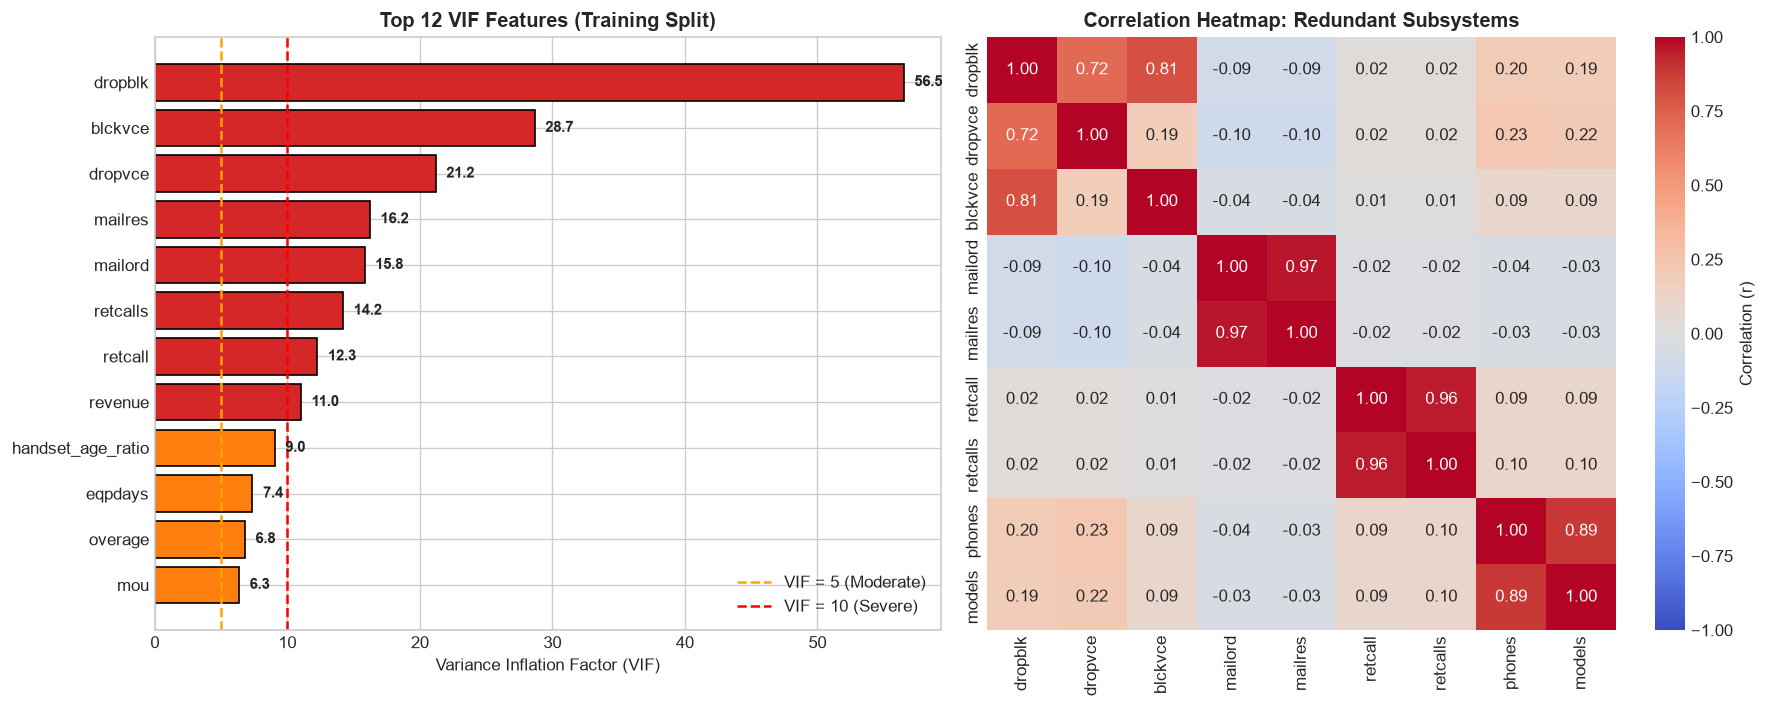

In [7]:
# Visualize Top VIFs and Collinear Subsystems
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top12_vif = vif_df.head(12).sort_values(by='VIF')
colors = ['#d62728' if v > 10 else ('#ff7f0e' if v > 5 else '#1f77b4') for v in top12_vif['VIF']]
axes[0].barh(top12_vif['Feature'], top12_vif['VIF'], color=colors, edgecolor='black')
axes[0].axvline(5, color='orange', linestyle='--', label='VIF = 5 (Moderate)')
axes[0].axvline(10, color='red', linestyle='--', label='VIF = 10 (Severe)')
axes[0].set_title("Top 12 VIF Features (Training Split)", fontweight='bold')
axes[0].set_xlabel("Variance Inflation Factor (VIF)")
axes[0].legend(loc='lower right')
for i, v in enumerate(top12_vif['VIF']):
    axes[0].text(v + 0.8, i, f"{v:.1f}", va='center', fontweight='bold', fontsize=9)

# Heatmap of key collinear pairs
collinear_cols = ['dropblk', 'dropvce', 'blckvce', 'mailord', 'mailres', 'retcall', 'retcalls', 'phones', 'models']
sns.heatmap(X_tr_scaled[collinear_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=axes[1], vmin=-1, vmax=1, cbar_kws={'label': 'Correlation (r)'})
axes[1].set_title("Correlation Heatmap: Redundant Subsystems", fontweight='bold')

plt.tight_layout()
plt.show()



### 📋 Summary of Multicollinearity Pruning Recommendations

| Redundant Pair / Subsystem | Diagnostic Metrics | Recommendation | Technical Rationale |
|---|---|---|---|
| **`dropblk`** vs **(`dropvce`, `blckvce`)** | $\text{VIF}(\text{dropblk}) = 56.45$<br>$\text{VIF}(\text{blckvce}) = 28.64$<br>$\text{VIF}(\text{dropvce}) = 21.18$ | **Remove `dropblk`**;<br>Retain `dropvce` and `blckvce`. | $96.66\%$ identical linear sum. Removing the composite eliminates extreme VIF while preserving specific call failure causes. |
| **`models`** vs **`phones`** | $r = 0.890$, $\text{VIF} = 5.78$ | **Remove `models`**;<br>Retain `phones`. | In $89\%$ of accounts, handset model count tracks handset unit count. `phones` is the cleaner hardware count. |
| **`mailres`** vs **`mailord`** | $r = 0.968$, $\text{VIF} \approx 16$ | **Remove `mailres`**;<br>Retain `mailord`. | $96.8\%$ correlation represents near-duplicate marketing indicators. |
| **`retcall`** vs **`retcalls`** | $r = 0.958$, $\text{VIF} = 12.3 - 14.2$ | **Retain `retcall`**;<br>Drop `retcalls` (or test in feature importance). | `retcall` is strictly equivalent to `(retcalls > 0)`. $92.3\%$ of active callers only call once. `retcall` has stronger correlation with churn. |
| **`revenue`**, **`mou`**, **`overage`** | $r = 0.71 - 0.79$, $\text{VIF} = 6.2 - 10.9$ | **RETAIN ALL THREE**.<br>*(Do not remove!)* | Although correlated, revenue, minutes, and overage represent distinct business drivers (billing burden vs volume vs penalty shock). Gradient boosted trees utilize interactions among them effectively. |



## 🏆 Section 4: Feature Importance & Feature Selection Comparison

### 🎯 Methodological Setup:
We evaluate feature contributions using three complementary paradigms strictly on the training partition:
1. **Random Forest (Embedded MDI):** Measures total variance reduction / Gini impurity drop across bagging trees.
2. **XGBoost (Embedded Gain):** Measures gradient loss reduction from splits on each feature across sequential boosting stages.
3. **Mutual Information (Filter Method):** Measures non-linear dependency $I(X; Y) = H(Y) - H(Y|X)$ independent of any model architecture.

### 🛡️ Test Set Isolation:
Feature selection criteria and rankings are computed **solely on $X_{\text{train}}$ and $y_{\text{train}}$** to prevent target leakage.


In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.feature_selection import mutual_info_classif

# 1. Apply verified multicollinearity pruning from Section 4.2
TO_REMOVE_COLLINEAR = ['dropblk', 'mailres', 'models', 'retcalls']
X_train_clean = X_train_eng.drop(columns=TO_REMOVE_COLLINEAR)

# 2. Impute training set
imputer = SimpleImputer(strategy='median')
X_tr_imp = pd.DataFrame(imputer.fit_transform(X_train_clean), columns=X_train_clean.columns, index=X_train_clean.index)

# 3. Fit Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_tr_imp, y_train)
rf_importance = pd.Series(rf.feature_importances_, index=X_train_clean.columns)

# 4. Fit XGBoost
xgb = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss')
xgb.fit(X_tr_imp, y_train)
xgb_importance = pd.Series(xgb.feature_importances_, index=X_train_clean.columns)

# 5. Compute Mutual Information
np.random.seed(42)
sample_idx = y_train.groupby(y_train, group_keys=False).apply(lambda s: s.sample(min(len(s), 7500), random_state=42)).index
mi_scores = mutual_info_classif(X_tr_imp.loc[sample_idx], y_train.loc[sample_idx], random_state=42)
mi_importance = pd.Series(mi_scores, index=X_train_clean.columns)

# Consolidated ranking
ranking_df = pd.DataFrame({
    'Random_Forest': rf_importance,
    'XGBoost': xgb_importance,
    'Mutual_Info': mi_importance
})
ranking_df['RF_Rank'] = ranking_df['Random_Forest'].rank(ascending=False).astype(int)
ranking_df['XGB_Rank'] = ranking_df['XGBoost'].rank(ascending=False).astype(int)
ranking_df['MI_Rank'] = ranking_df['Mutual_Info'].rank(ascending=False).astype(int)
ranking_df['Consensus_Rank'] = np.round((ranking_df['RF_Rank'] + ranking_df['XGB_Rank'] + ranking_df['MI_Rank']) / 3, 2)
ranking_df = ranking_df.sort_values(by='Consensus_Rank')

print("=== Top 15 Consensus Churn Predictors ===")
ranking_df.head(15)[['Random_Forest', 'XGBoost', 'Mutual_Info', 'Consensus_Rank']]



=== Top 15 Consensus Churn Predictors ===


,Random_Forest,XGBoost,Mutual_Info,Consensus_Rank
eqpdays,0.089317,0.079708,0.016148,1.67
months,0.075568,0.040991,0.023614,2.00
handset_age_ratio,0.052771,0.019377,0.019202,6.00
changem,0.051428,0.021901,0.010244,7.00
cost_per_mou,0.048964,0.023864,0.008490,8.00
recchrge,0.036106,0.018039,0.011205,9.67
peakvce,0.028345,0.017168,0.011936,10.67
mou,0.050282,0.028190,0.004574,11.33
age1,0.023518,0.019297,0.010617,12.00
overage_burden,0.026201,0.022611,0.005217,12.33


In [9]:
# Evaluate performance of engineered features
engineered_list = ['handset_age_ratio', 'cost_per_mou', 'overage_burden', 'usage_drop_severe', 'network_friction_rate']

print("=== Engineered Features Validation Summary ===")
eng_summary = ranking_df.loc[engineered_list][['RF_Rank', 'XGB_Rank', 'MI_Rank', 'Consensus_Rank']]
eng_summary



=== Engineered Features Validation Summary ===


,RF_Rank,XGB_Rank,MI_Rank,Consensus_Rank
handset_age_ratio,3,13,2,6.00
cost_per_mou,6,8,10,8.00
overage_burden,12,9,16,12.33
usage_drop_severe,43,64,55,54.00
network_friction_rate,10,20,13,14.33


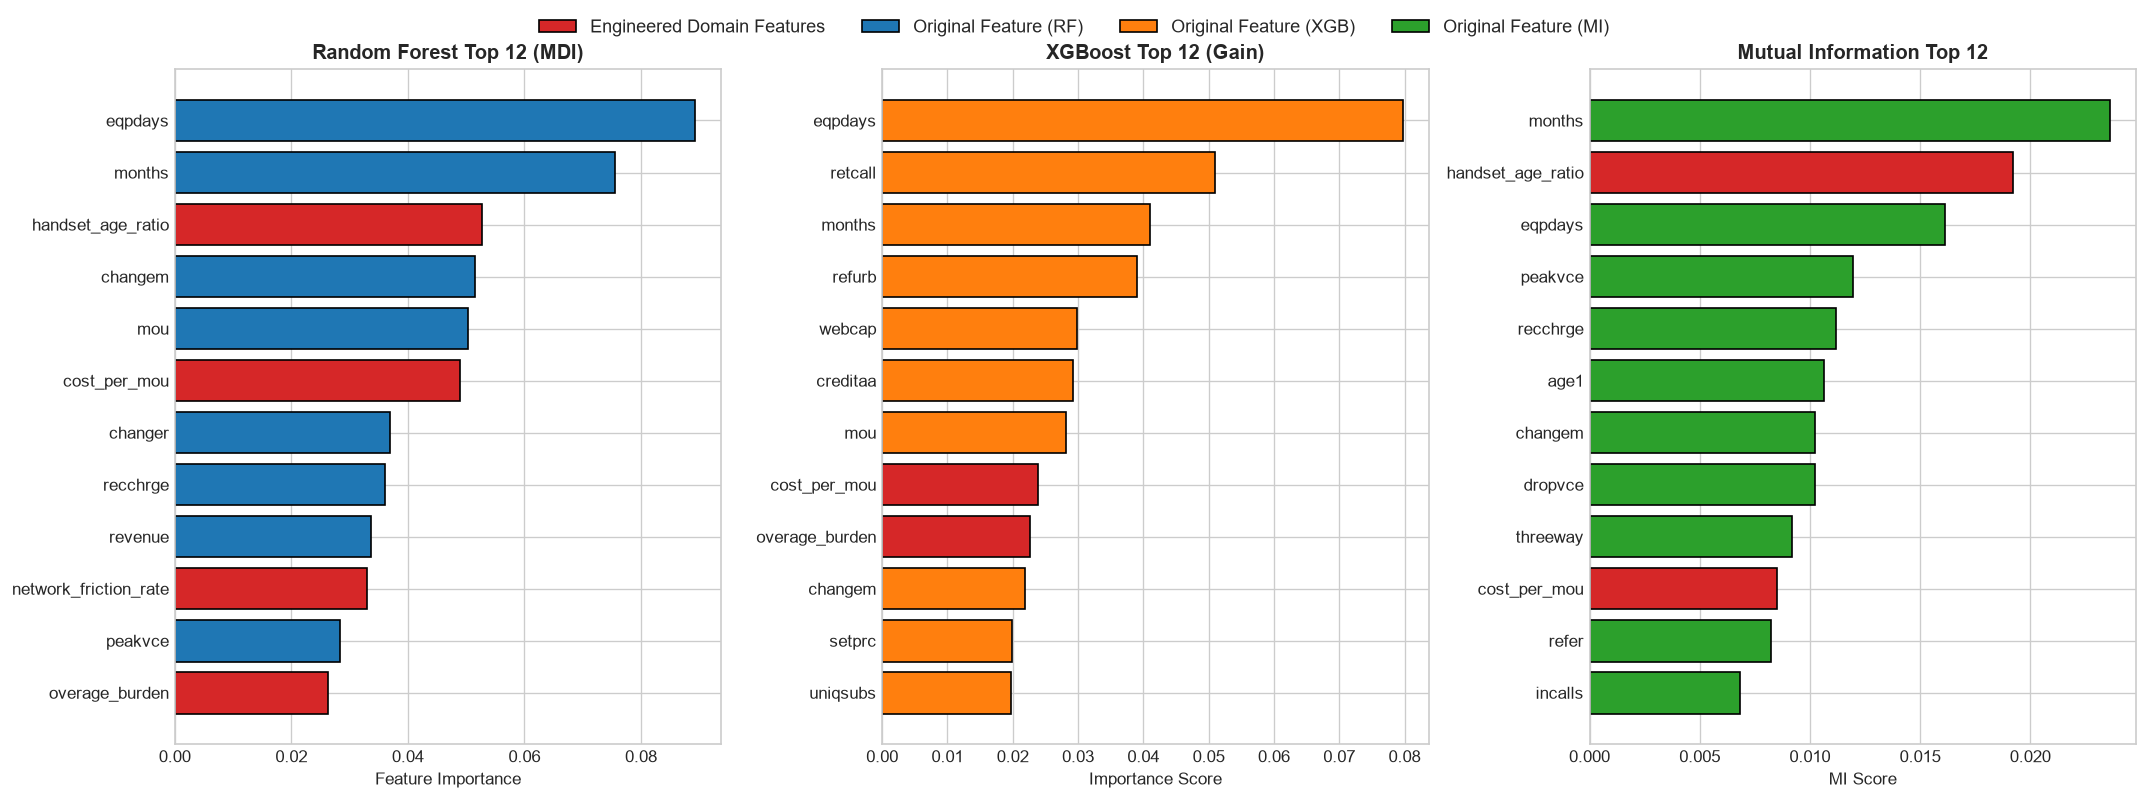

In [10]:
# Visualization: Comparison across all three methods
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))

top12_rf = rf_importance.sort_values(ascending=False).head(12)
rf_colors = ['#d62728' if feat in engineered_list else '#1f77b4' for feat in top12_rf.index]
axes[0].barh(top12_rf.index[::-1], top12_rf.values[::-1], color=rf_colors[::-1], edgecolor='black')
axes[0].set_title("Random Forest Top 12 (MDI)", fontweight='bold')
axes[0].set_xlabel("Feature Importance")

top12_xgb = xgb_importance.sort_values(ascending=False).head(12)
xgb_colors = ['#d62728' if feat in engineered_list else '#ff7f0e' for feat in top12_xgb.index]
axes[1].barh(top12_xgb.index[::-1], top12_xgb.values[::-1], color=xgb_colors[::-1], edgecolor='black')
axes[1].set_title("XGBoost Top 12 (Gain)", fontweight='bold')
axes[1].set_xlabel("Importance Score")

top12_mi = mi_importance.sort_values(ascending=False).head(12)
mi_colors = ['#d62728' if feat in engineered_list else '#2ca02c' for feat in top12_mi.index]
axes[2].barh(top12_mi.index[::-1], top12_mi.values[::-1], color=mi_colors[::-1], edgecolor='black')
axes[2].set_title("Mutual Information Top 12", fontweight='bold')
axes[2].set_xlabel("MI Score")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#d62728', edgecolor='black', label='Engineered Domain Features'),
    Patch(facecolor='#1f77b4', edgecolor='black', label='Original Feature (RF)'),
    Patch(facecolor='#ff7f0e', edgecolor='black', label='Original Feature (XGB)'),
    Patch(facecolor='#2ca02c', edgecolor='black', label='Original Feature (MI)')
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=4, fontsize=11)
plt.tight_layout()
plt.show()



### 📋 Final Feature Selection & Serialization
We preserve features demonstrating non-zero predictive contribution across models, while discarding uninformative, zero-gain variables (`callfwdv`, rare occupation dummies with 0.000 importance).


In [11]:
# Filter zero-gain uninformative features
zero_gain = [f for f in X_train_clean.columns if xgb_importance[f] == 0.0 and rf_importance[f] < 0.002]
final_features = [f for f in X_train_clean.columns if f not in zero_gain]

print(f"Features Before Selection : {X_train_clean.shape[1]}")
print(f"Zero-Gain Pruned Features : {len(zero_gain)} ({zero_gain})")
print(f"Final Retained Features   : {len(final_features)}")

# Save selected feature list
with open('../data/processed/selected_features.json', 'w') as f:
    json.dump({'selected_features': final_features, 'count': len(final_features)}, f, indent=4)

print("[+] Successfully exported selected features list to data/processed/selected_features.json")



Features Before Selection : 67
Zero-Gain Pruned Features : 4 (['callfwdv', 'occcrft', 'occstud', 'occself'])
Final Retained Features   : 63
[+] Successfully exported selected features list to data/processed/selected_features.json
